<div style="background: linear-gradient(135deg,#0A0E3D 0%,#1A237E 100%);
            padding:40px 36px 32px 36px;
            border-radius:12px;
            color:white;
            font-family:Arial,sans-serif">

<div style="font-size:13px; letter-spacing:2px; opacity:.75; margin-bottom:8px">
UNIVERSIDAD EXTERNADO DE COLOMBIA · CIENCIA DE DATOS · 2026
</div>

<h1 style="margin:0 0 6px 0; font-size:28px; font-weight:700; line-height:1.2">
EDA — SPARCS (Hospital Inpatient Discharges)
</h1>

<h2 style="margin:0 0 20px 0; font-size:17px; font-weight:400; opacity:.9">
Análisis exploratorio del dataset público de Nueva York, 2021
</h2>

<hr style="border:none; border-top:1px solid rgba(255,255,255,.3); margin:0 0 18px 0"/>

<div style="display:flex; gap:40px; font-size:13px; opacity:.85">

<div>
<b>Autores:</b><br>
Daniel Vallejo Vecil<br>
Juliana Muñoz González
</div>

<div>
<b>Director:</b><br>
Julián F. Sánchez López
</div>

<div>
<b>Capa construida:</b><br>
1_bronze
</div>

</div>

</div>

<div style="background:#1A237E;
padding:18px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h2 style="margin:0;">
1. Objetivo
</h2>

</div>

<div style="background:#EEF0FA;
border-left:6px solid #1A237E;
padding:18px;
border-radius:0 0 8px 8px;
font-family:Arial,sans-serif">


Este notebook explora el dataset público <b>SPARCS 2021</b> (Statewide Planning and Research
Cooperative System, Nueva York), 33 variables según el diccionario de datos oficial
(<code>NYSDOH_SPARCS_De-Identified_Data_Dictionary_2021.pdf</code>). El objetivo es:

<ol>
<li>Caracterizar la variable objetivo <code>Length of Stay</code> y las 32 variables predictoras
disponibles (numéricas y categóricas).</li>
<li>Identificar qué variables no aportan valor (identificadores, columnas prácticamente constantes)
para excluirlas.</li>
<li>Dejar documentado qué variables pasan a la etapa de <code>02_Preprocessing</code> — este notebook
<b>no limpia ni transforma</b> el dataset, solo explora.</li>
</ol>

</div>

<div style="background:#1A237E;
padding:18px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h2 style="margin:0;">
2. Carga de datos
</h2>

</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
import re
from scipy import stats as sstats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

plt.rcParams["figure.facecolor"] = "white"
COLOR_PRIMARY = "#1A237E"
COLOR_SECONDARY = "#5C6BC0"

RAW_FILE = "../data/1_bronze/Hospital_Inpatient_Discharges_(SPARCS_De-Identified)__2021_20260906.csv"

df = pd.read_csv(RAW_FILE, low_memory=False)

print(f"Filas:    {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")
df.head(3)


Filas:    2,135,260
Columnas: 33


,Hospital Service Area,Hospital County,Operating Certificate Number,Permanent Facility Id,Facility Name,Age Group,Zip Code - 3 digits,Gender,Race,Ethnicity,Length of Stay,Type of Admission,Patient Disposition,Discharge Year,CCSR Diagnosis Code,CCSR Diagnosis Description,CCSR Procedure Code,CCSR Procedure Description,APR DRG Code,APR DRG Description,APR MDC Code,APR MDC Description,APR Severity of Illness Code,APR Severity of Illness Description,APR Risk of Mortality,APR Medical Surgical Description,Payment Typology 1,Payment Typology 2,Payment Typology 3,Birth Weight,Emergency Department Indicator,Total Charges,Total Costs
0,New York City,Bronx,7000006.0,1169.0,Montefiore Medical Center - Henry & Lucy Moses...,70 or Older,104,M,Other Race,Spanish/Hispanic,27,Emergency,Home w/ Home Health Services,2021,INF012,COVID-19,OTR004,ISOLATION PROCEDURES,137,MAJOR RESPIRATORY INFECTIONS AND INFLAMMATIONS,4,DISEASES AND DISORDERS OF THE RESPIRATORY SYSTEM,3,Major,Extreme,Medical,Medicare,Medicaid,NaN,NaN,Y,"$320,922.43","$60,241.34"
1,New York City,Bronx,7000006.0,1169.0,Montefiore Medical Center - Henry & Lucy Moses...,50 to 69,104,F,White,Not Span/Hispanic,4,Emergency,Home or Self Care,2021,NVS005,Multiple sclerosis,NaN,NaN,43,"MULTIPLE SCLEROSIS, OTHER DEMYELINATING DISEAS...",1,DISEASES AND DISORDERS OF THE NERVOUS SYSTEM,2,Moderate,Minor,Medical,Private Health Insurance,NaN,NaN,NaN,Y,"$61,665.22","$9,180.69"
2,New York City,Bronx,7000006.0,1168.0,Montefiore Medical Center-Wakefield Hospital,18 to 29,104,F,Other Race,Spanish/Hispanic,2,Emergency,Home or Self Care,2021,PRG016,Previous C-section,PGN003,CESAREAN SECTION,540,CESAREAN SECTION WITHOUT STERILIZATION,14,"PREGNANCY, CHILDBIRTH AND THE PUERPERIUM",1,Minor,Minor,Surgical,Medicaid,NaN,NaN,NaN,N,"$42,705.34","$11,366.5"


> ### Guardar tablas en /tablas

In [2]:
# ==========================================================
# Helper: guardar cualquier tabla destinada a la tesis en tablas/
# Nomenclatura: XX_NombreTabla.csv, donde XX es el numeral de este notebook
# ==========================================================

NOTEBOOK_NUM = "01"
TABLAS_PATH = Path("../tablas")
TABLAS_PATH.mkdir(parents=True, exist_ok=True)


def sanitizar_nombre(nombre):
    """Convierte un nombre de variable en un sufijo de archivo válido (sin espacios ni símbolos)."""
    nombre = nombre.replace(" ", "")
    nombre = re.sub(r"[^A-Za-z0-9_]", "", nombre)
    return nombre


def guardar_tabla(tabla, nombre):
    """Guarda un DataFrame/Series en ../tablas/ con nomenclatura NOTEBOOK_NUM_nombre.csv"""
    if isinstance(tabla, pd.Series):
        tabla = tabla.to_frame()
    archivo = TABLAS_PATH / f"{NOTEBOOK_NUM}_{nombre}.csv"
    tabla.to_csv(archivo, encoding="utf-8-sig")
    print(f"Tabla guardada: {archivo.resolve()}")


In [3]:
print("Nombres de columnas tal como los lee pandas:")
for c in df.columns:
    print(f"  - {c!r}")


Nombres de columnas tal como los lee pandas:
  - 'Hospital Service Area'
  - 'Hospital County'
  - 'Operating Certificate Number'
  - 'Permanent Facility Id'
  - 'Facility Name'
  - 'Age Group'
  - 'Zip Code - 3 digits'
  - 'Gender'
  - 'Race'
  - 'Ethnicity'
  - 'Length of Stay'
  - 'Type of Admission'
  - 'Patient Disposition'
  - 'Discharge Year'
  - 'CCSR Diagnosis Code'
  - 'CCSR Diagnosis Description'
  - 'CCSR Procedure Code'
  - 'CCSR Procedure Description'
  - 'APR DRG Code'
  - 'APR DRG Description'
  - 'APR MDC Code'
  - 'APR MDC Description'
  - 'APR Severity of Illness Code'
  - 'APR Severity of Illness Description'
  - 'APR Risk of Mortality'
  - 'APR Medical Surgical Description'
  - 'Payment Typology 1'
  - 'Payment Typology 2'
  - 'Payment Typology 3'
  - 'Birth Weight'
  - 'Emergency Department Indicator'
  - 'Total Charges'
  - 'Total Costs'


<div style="background:#FFF5F5;
border-left:6px solid #C62828;
padding:18px;
border-radius:0 0 8px 8px;
font-family:Arial,sans-serif">


Ejecuta la celda anterior primero: los nombres reales de columna en el CSV pueden variar levemente
(mayúsculas, guiones bajos en vez de espacios, etc.) respecto al diccionario oficial. Si el resto del
notebook falla con <code>KeyError</code>, ajusta el diccionario <code>COLUMNAS</code> de la siguiente
celda con los nombres exactos que imprimió esta celda.


</div>

<div style="background:#1A237E;
padding:18px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h2 style="margin:0;">
3. Clasificación de variables (según el diccionario oficial)
</h2>

</div>

In [27]:
# Ajusta estas listas si los nombres reales de columna difieren de los del diccionario oficial

IDENTIFICADORES = [
    "Operating Certificate Number",
    "Permanent Facility Id",
    "Facility Name",
]

OBJETIVO = "Length of Stay"

CATEGORICAS = [
    "Hospital Service Area",
    "Hospital County",
    "Age Group",
    "Zip Code - 3 digits",
    "Gender",
    "Race",
    "Ethnicity",
    "Type of Admission",
    "Discharge Year",
    "CCSR Diagnosis Code",
    "CCSR Diagnosis Description",
    "CCSR Procedure Code",
    "CCSR Procedure Description",
    "APR DRG Code",
    "APR DRG Description",
    "APR MDC Code",
    "APR MDC Description",
    "APR Severity of Illness Code",
    "APR Severity of Illness Description",
    "APR Risk of Mortality",
    "APR Medical Surgical Description",
    "Payment Typology 1",
    "Payment Typology 2",
    "Payment Typology 3",
    "Emergency Department Indicator",
]

NUMERICAS = [
    "Birth Weight"

]

VARIABLES_PAGO = [
    "Total Charges",
    "Total Costs",
    "Patient Disposition"
]

todas = IDENTIFICADORES + [OBJETIVO] + CATEGORICAS + NUMERICAS
faltantes = [c for c in todas if c not in df.columns]
print(f"Columnas esperadas no encontradas en el CSV: {faltantes}")
print(f"Columnas del CSV no clasificadas arriba: {[c for c in df.columns if c not in todas]}")


Columnas esperadas no encontradas en el CSV: []
Columnas del CSV no clasificadas arriba: ['Patient Disposition', 'Total Charges', 'Total Costs']


<div style="background:#1A237E;
padding:18px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h2 style="margin:0;">
4. Mapa de valores faltantes
</h2>

</div>

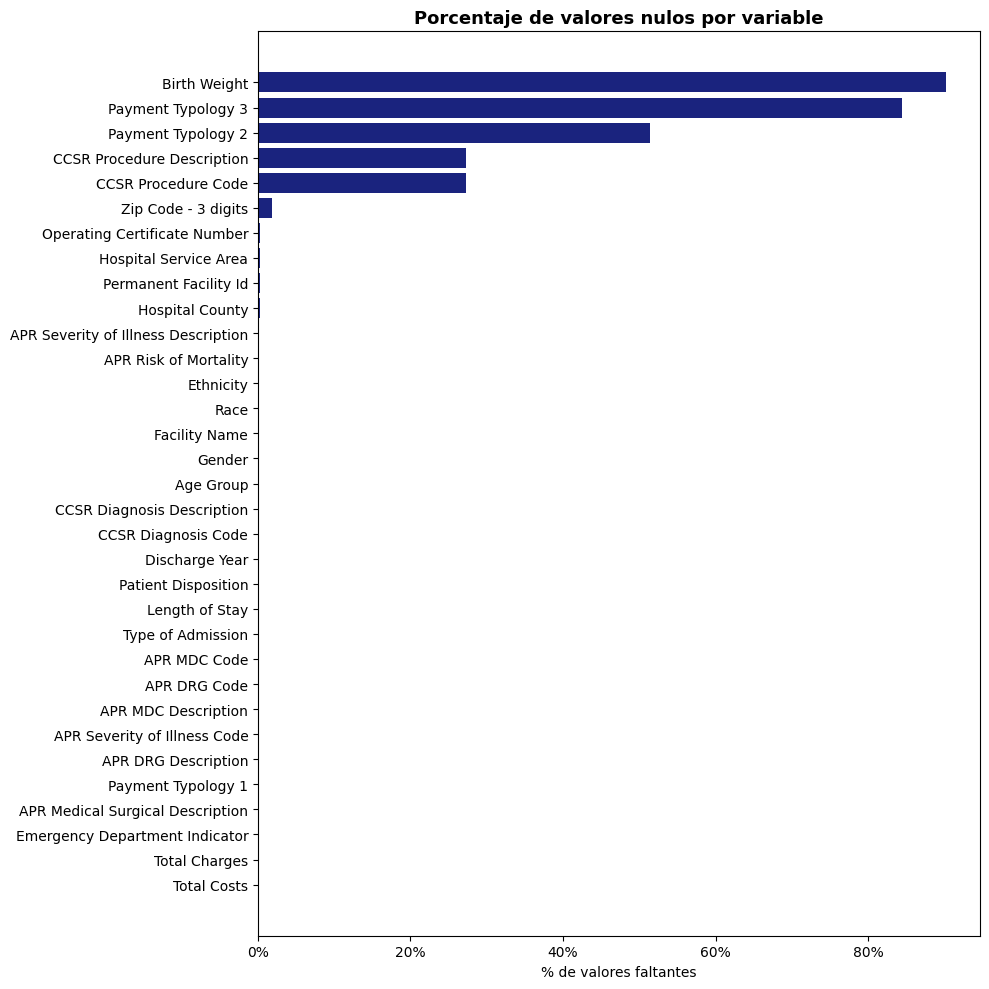

,% nulos
Birth Weight,90.17
Payment Typology 3,84.44
Payment Typology 2,51.38
CCSR Procedure Description,27.31
CCSR Procedure Code,27.31
Zip Code - 3 digits,1.88
Operating Certificate Number,0.31
Hospital Service Area,0.24
Permanent Facility Id,0.24
Hospital County,0.24


Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_ValoresFaltantes.csv


In [5]:
nulos = (df.isna().mean() * 100).round(2).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 10))
colors = [COLOR_PRIMARY if v > 0 else "#CCCCCC" for v in nulos.values]
ax.barh(nulos.index[::-1], nulos.values[::-1], color=colors[::-1])
ax.set_xlabel("% de valores faltantes")
ax.set_title("Porcentaje de valores nulos por variable", fontsize=13, fontweight="bold")
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
plt.tight_layout()
plt.show()

display(nulos.to_frame("% nulos"))
guardar_tabla(nulos.to_frame("pct_nulos"), "ValoresFaltantes")


<div style="background:#1A237E;
padding:18px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h2 style="margin:0;">
5. Variable objetivo: Length of Stay
</h2>

</div>

<div style="background:#F5F9FF;
border-left:6px solid #1565C0;
padding:18px;
border-radius:0 0 8px 8px;
font-family:Arial,sans-serif">


Según el diccionario, esta variable llega como <b>texto</b>, y los valores ≥120 días están agregados
como <code>"120+"</code>. Hay que limpiarla antes de poder describirla numéricamente (esta limpieza
puntual se hace aquí, en el EDA, solo para poder analizarla — la limpieza definitiva para el modelo
se hace en <code>02_Preprocessing</code>).


</div>

In [6]:
print("Valores únicos de Length of Stay (muestra):")
print(df[OBJETIVO].astype(str).unique()[:20])
print()
print(f"¿Existen valores '120+'? {(df[OBJETIVO].astype(str).str.contains('120', na=False)).sum()} registros")


Valores únicos de Length of Stay (muestra):
<ArrowStringArray>
['27', '4', '2', '5', '3', '6', '1', '21', '9', '14', '19', '24', '16', '7', '8', '11', '13', '10', '28', '120 +']
Length: 20, dtype: str

¿Existen valores '120+'? 1575 registros


In [7]:
los_raw = df[OBJETIVO].astype(str).str.strip()
los_num = pd.to_numeric(los_raw.str.replace("120 +", "120", regex=False), errors="coerce")

print(f"n válidos tras limpieza: {los_num.notna().sum():,} / {len(los_num):,}")
print(f"Registros que no pudieron convertirse a número: {los_num.isna().sum() - df[OBJETIVO].isna().sum()}")
print()
estadisticas_los = los_num.dropna().describe(percentiles=[.05, .25, .5, .75, .90, .95, .99]).round(2)
print(estadisticas_los)

guardar_tabla(estadisticas_los.to_frame("Length of Stay"), "EstadisticasLengthOfStay")


n válidos tras limpieza: 2,135,260 / 2,135,260
Registros que no pudieron convertirse a número: 0

count    2135260.00
mean           5.75
std            8.41
min            1.00
5%             1.00
25%            2.00
50%            3.00
75%            6.00
90%           12.00
95%           19.00
99%           40.00
max          120.00
Name: Length of Stay, dtype: float64
Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_EstadisticasLengthOfStay.csv


In [8]:
los_validos = los_num.dropna()
print(f"Asimetría (skew): {sstats.skew(los_validos):.3f}")
print(f"Curtosis: {sstats.kurtosis(los_validos):.3f}")
print(f"Moda: {los_validos.mode().tolist()[:3]}")
print(f"% con estancia agregada en '120+' (valor=120): {(los_validos==120).mean()*100:.3f}%")
print(f"% con estancia == 1 día: {(los_validos==1).mean()*100:.2f}%")
print(f"% con estancia prolongada (>=7 días): {(los_validos>=7).mean()*100:.2f}%")


Asimetría (skew): 5.821
Curtosis: 52.959
Moda: [2]
% con estancia agregada en '120+' (valor=120): 0.074%
% con estancia == 1 día: 17.60%
% con estancia prolongada (>=7 días): 24.12%


Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_Distribución_LengthofStay.csv


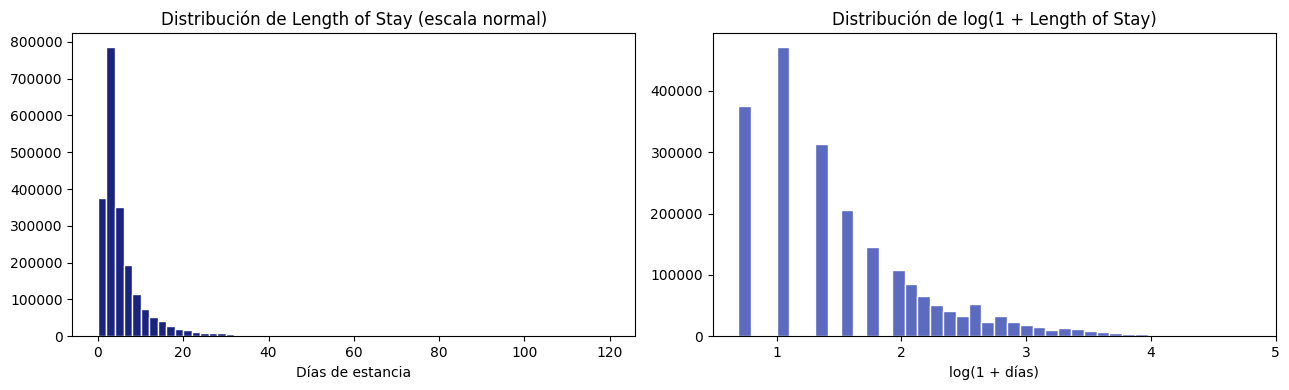

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(los_validos, bins=range(0, 121, 2), color=COLOR_PRIMARY, edgecolor="white")
axes[0].set_title("Distribución de Length of Stay (escala normal)")
axes[0].set_xlabel("Días de estancia")

axes[1].hist(np.log1p(los_validos), bins=40, color=COLOR_SECONDARY, edgecolor="white")
axes[1].set_title("Distribución de log(1 + Length of Stay)")
axes[1].set_xlabel("log(1 + días)")

guardar_tabla(los_validos.to_frame("Length of Stay"), "Distribución_LengthofStay")

plt.tight_layout()
plt.show()


<div style="background:#1A237E;
padding:18px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h2 style="margin:0;">
6. Variables categóricas
</h2>

</div>

In [11]:
resumen_categoricas = []
for c in CATEGORICAS:
    if c not in df.columns:
        continue
    s = df[c]
    resumen_categoricas.append({
        "variable": c,
        "n_categorias": s.nunique(),
        "pct_nulos": round(s.isna().mean() * 100, 2),
    })
resumen_df = pd.DataFrame(resumen_categoricas).sort_values("n_categorias", ascending=False)
display(resumen_df)

guardar_tabla(resumen_df, "ResumenCategoricas")


,variable,n_categorias,pct_nulos
9,CCSR Diagnosis Code,478,0.00
10,CCSR Diagnosis Description,478,0.00
14,APR DRG Description,334,0.00
13,APR DRG Code,334,0.00
12,CCSR Procedure Description,321,27.31
11,CCSR Procedure Code,321,27.31
1,Hospital County,57,0.24
3,Zip Code - 3 digits,50,1.88
15,APR MDC Code,26,0.00
16,APR MDC Description,26,0.00


Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_ResumenCategoricas.csv


<div style="background:#1976D2;
padding:15px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h3 style="margin:0;">
6.1 Distribuciones (top 15 categorías por variable)
</h3>

</div>

In [12]:
for c in CATEGORICAS:
    if c not in df.columns:
        continue
    s = df[c]
    n_valid = s.notna().sum()
    if n_valid == 0:
        print(f"--- {c}: sin datos ---\n")
        continue
    vc = s.value_counts(dropna=True).head(15)
    vc_pct = (vc / n_valid * 100).round(2)
    tabla = pd.DataFrame({"conteo": vc, "pct": vc_pct})
    print(f"--- {c}  (n_validos={n_valid:,}, nulos={s.isna().mean()*100:.1f}%, n_categorias={s.nunique()}) ---")
    display(tabla)
    guardar_tabla(tabla, f"Distribucion_{sanitizar_nombre(c)}")
    print()


--- Hospital Service Area  (n_validos=2,130,046, nulos=0.2%, n_categorias=8) ---


,conteo,pct
Hospital Service Area,,
New York City,948517,44.53
Long Island,341506,16.03
Hudson Valley,230551,10.82
Central NY,147567,6.93
Capital/Adirond,146581,6.88
Western NY,144114,6.77
Finger Lakes,143503,6.74
Southern Tier,27707,1.30


Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_Distribucion_HospitalServiceArea.csv

--- Hospital County  (n_validos=2,130,046, nulos=0.2%, n_categorias=57) ---


,conteo,pct
Hospital County,,
Manhattan,366442,17.20
Kings,197218,9.26
Nassau,183953,8.64
Queens,171747,8.06
Bronx,163160,7.66
Suffolk,157553,7.40
Westchester,115317,5.41
Erie,111403,5.23
Monroe,108769,5.11


Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_Distribucion_HospitalCounty.csv

--- Age Group  (n_validos=2,135,260, nulos=0.0%, n_categorias=5) ---


...

Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_Distribucion_PaymentTypology2.csv

--- Payment Typology 3  (n_validos=332,152, nulos=84.4%, n_categorias=9) ---


,conteo,pct
Payment Typology 3,,
Self-Pay,204561,61.59
Medicaid,71460,21.51
Private Health Insurance,26171,7.88
Blue Cross/Blue Shield,12902,3.88
Medicare,10821,3.26
Miscellaneous/Other,3308,1.00
Federal/State/Local/VA,2277,0.69
"Managed Care, Unspecified",628,0.19
Department of Corrections,24,0.01


Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_Distribucion_PaymentTypology3.csv

--- Emergency Department Indicator  (n_validos=2,135,260, nulos=0.0%, n_categorias=2) ---


,conteo,pct
Emergency Department Indicator,,
Y,1335897,62.56
N,799363,37.44


Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_Distribucion_EmergencyDepartmentIndicator.csv



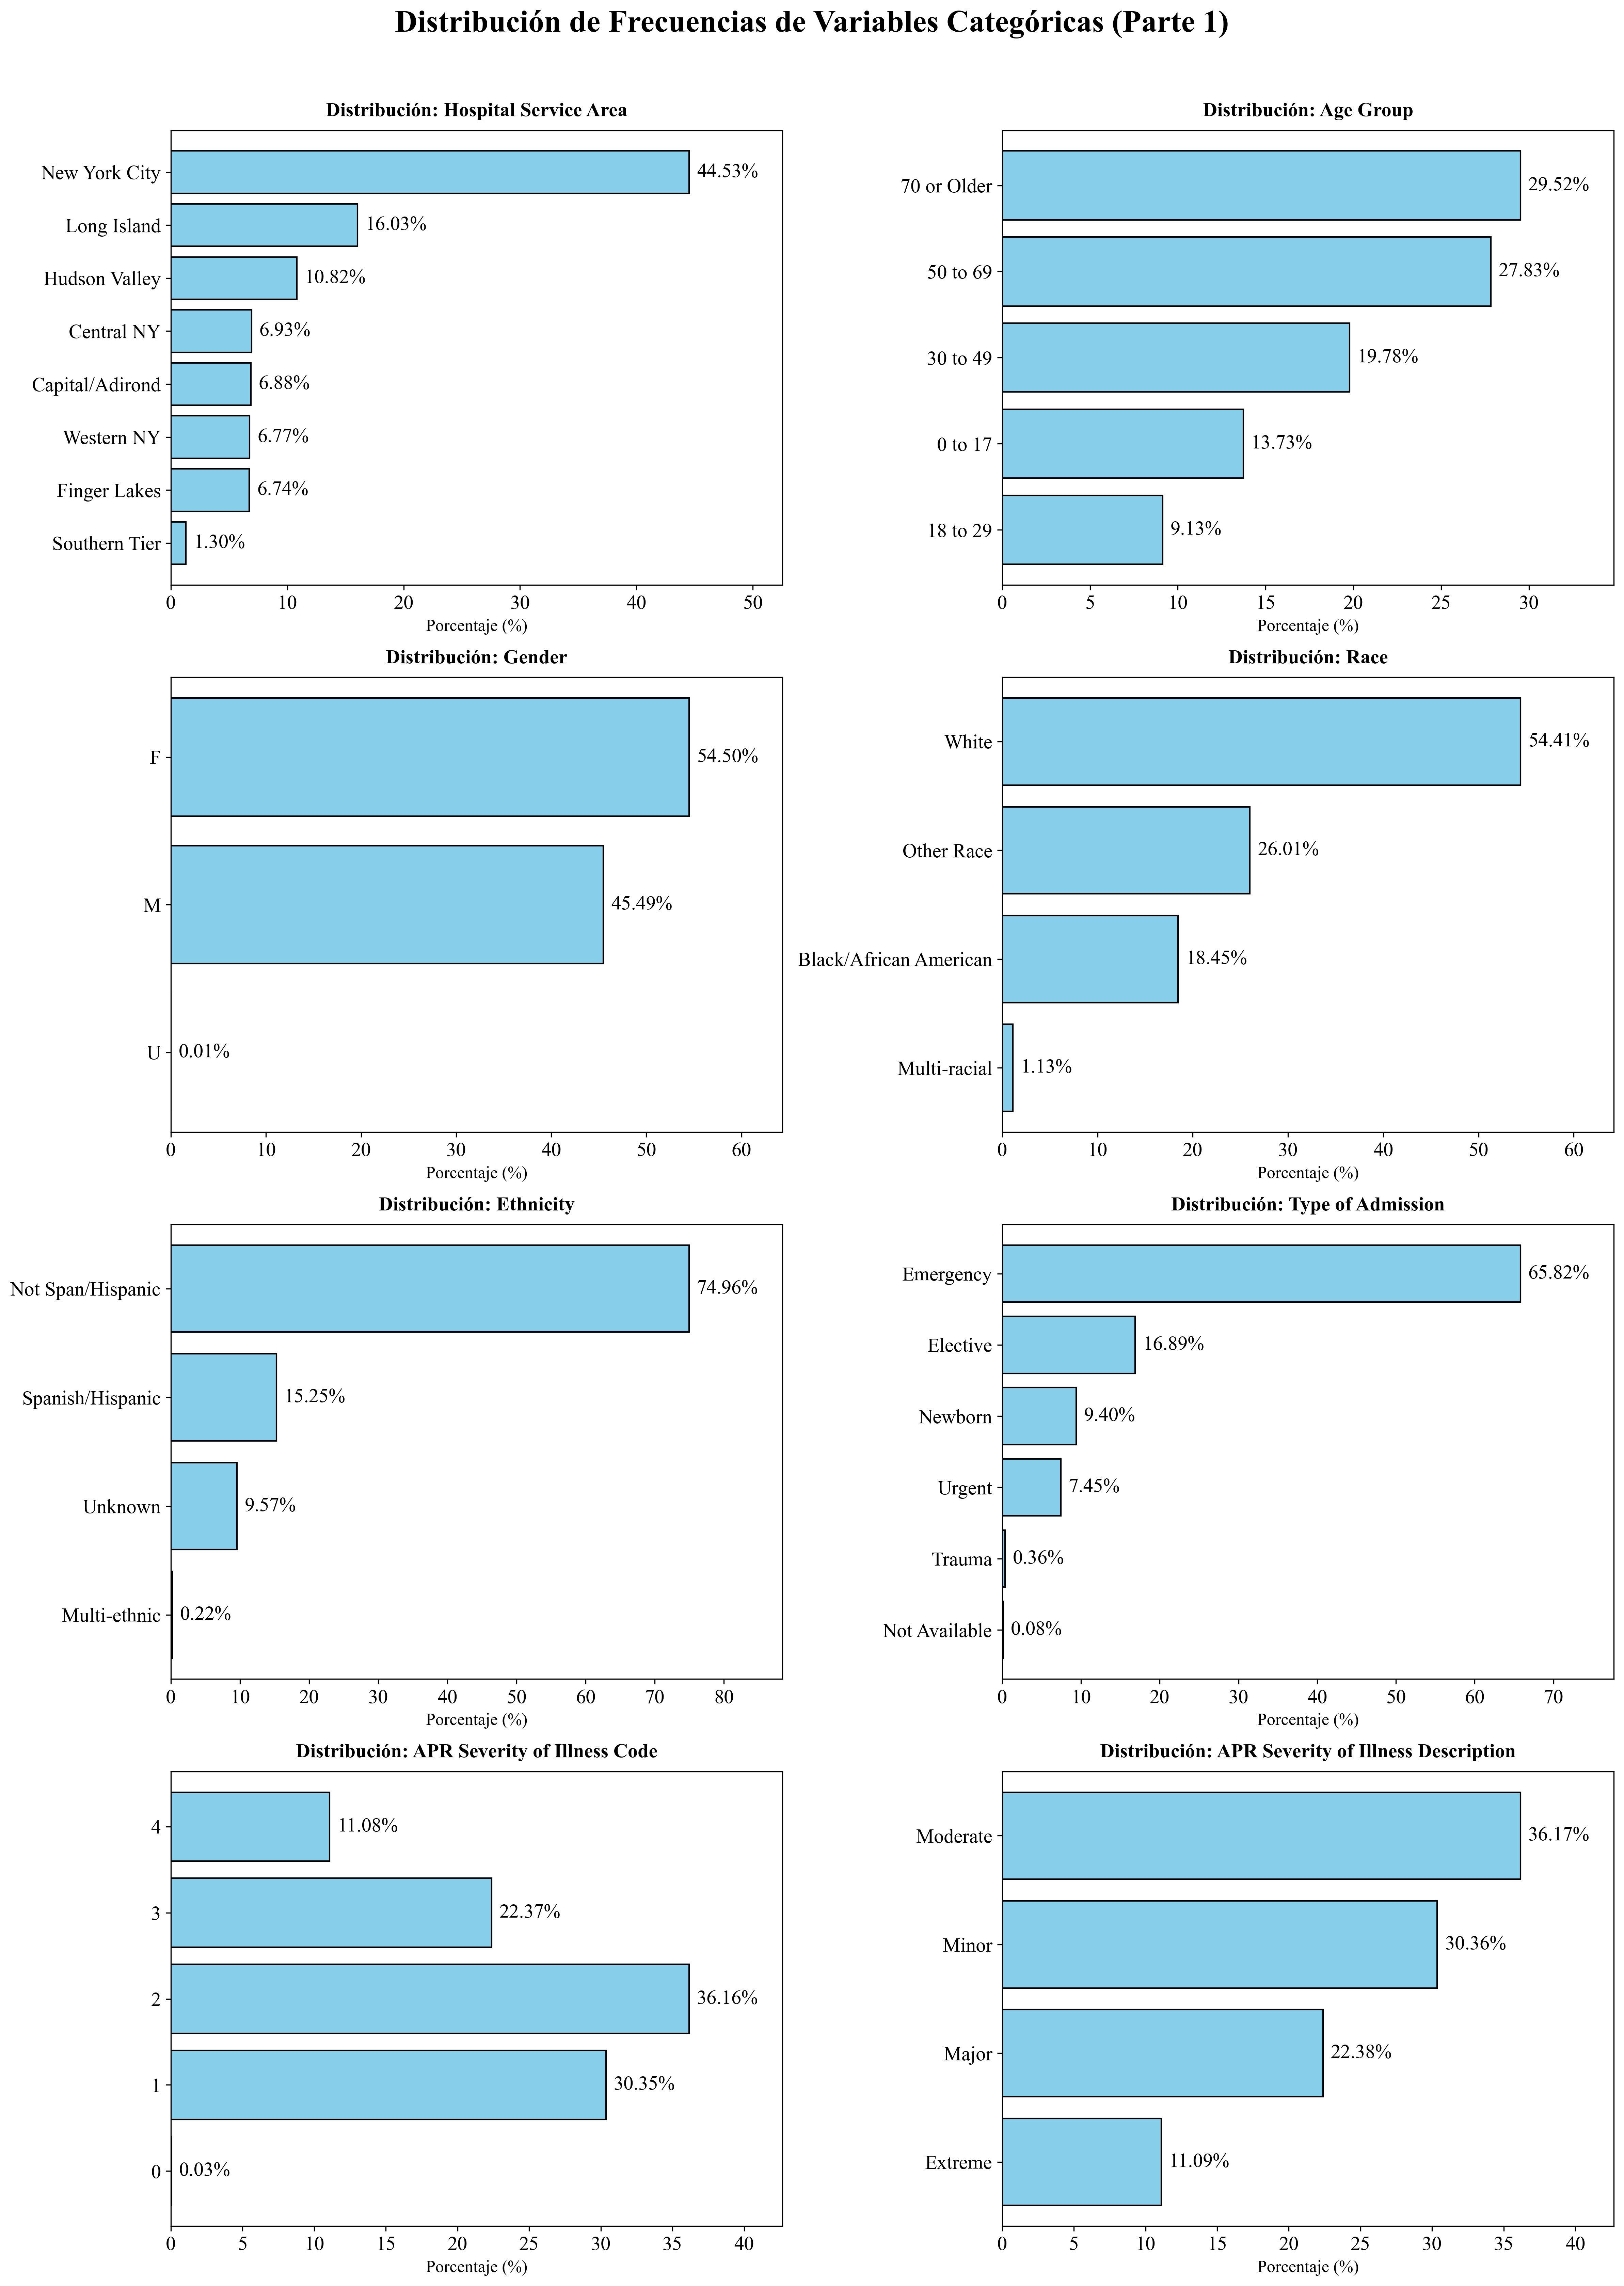

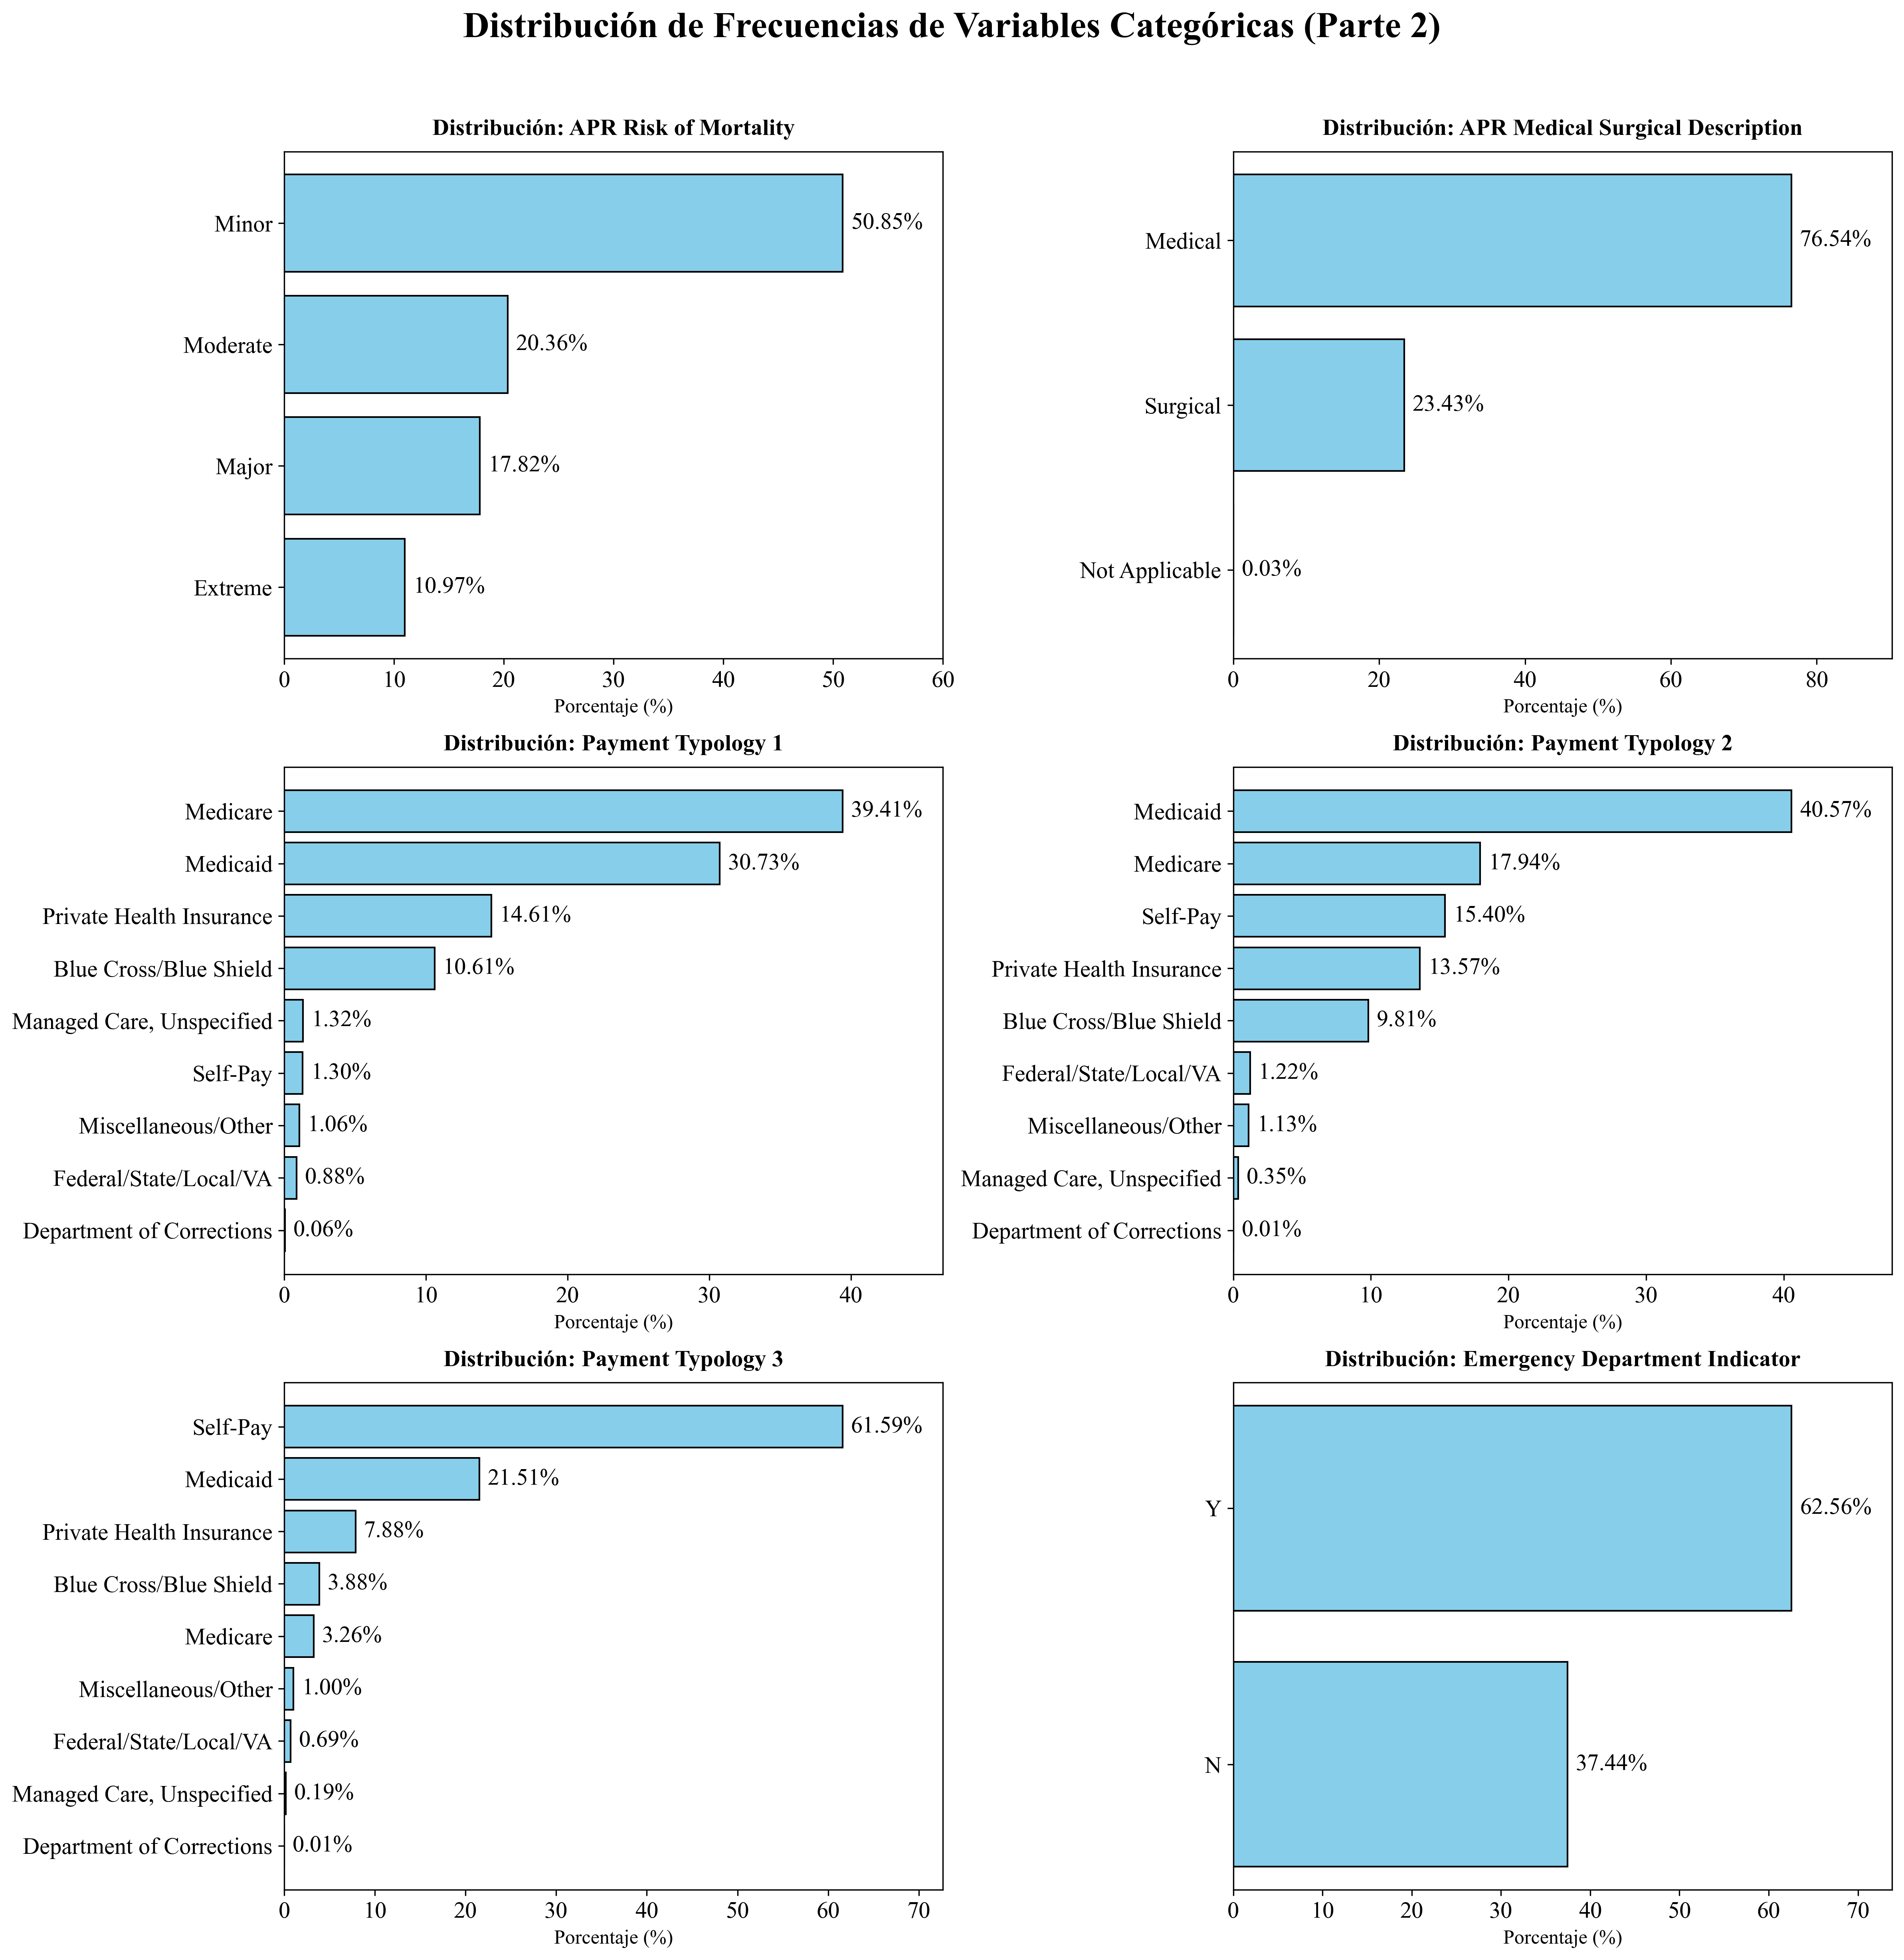

In [24]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Configurar tipografía Times New Roman de forma nativa (compatible con tu tesis)
plt.rcParams.update(
    {
        "text.usetex": False,
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "Liberation Serif"],
        "mathtext.fontset": "stix",
    }
)


# --- FUNCIÓN PARA ABREVIAR LA VARIABLE APR MDC DESCRIPTION ---
def formatear_aprmdc(texto):
    if pd.isna(texto):
        return texto
    palabras = str(texto).split()
    if not palabras:
        return ""

    # Primera palabra con la inicial en mayúscula y el resto en minúscula
    primera = palabras[0].capitalize()

    # Para el resto de palabras, dejar solo la inicial en mayúscula seguida de un punto
    iniciales = [f"{p[0].upper()}." for p in palabras[1:]]

    # Unir todo
    return " ".join([primera] + iniciales)


# --- Lista de tus 14 variables ---
CATEGORICAS = [
    "Hospital Service Area",
    "Age Group",
    "Gender",
    "Race",
    "Ethnicity",
    "Type of Admission",
    "APR Severity of Illness Code",
    "APR Severity of Illness Description",
    "APR Risk of Mortality",
    "APR Medical Surgical Description",
    "Payment Typology 1",
    "Payment Typology 2",
    "Payment Typology 3",
    "Emergency Department Indicator",
]

# Dividir la lista en dos bloques para las dos figuras
categoricas_fig1 = CATEGORICAS[:8]  # Primeras 8 variables (4 filas x 2 columnas = 8)
categoricas_fig2 = CATEGORICAS[
    8:
]  # Restantes 6 variables (3 filas x 2 columnas = 6)


# --- FUNCIÓN AUXILIAR PARA GENERAR CADA FIGURA ---
def generar_figura_bloque(
    lista_variables, filas, columnas, alto_figura, titulo_global, nombre_archivo
):
    fig, axes = plt.subplots(filas, columnas, figsize=(16, alto_figura), dpi=300)
    axes_flat = axes.flatten()

    idx_plot = 0

    for c in lista_variables:
        if c not in df.columns:
            continue

        s = df[c]
        n_valid = s.notna().sum()
        if n_valid == 0:
            continue

        # Obtener el Top 15 de categorías
        vc = s.value_counts(dropna=True).head(15)
        vc_pct = (vc / n_valid * 100).round(2)

        if idx_plot >= len(axes_flat):
            break

        ax = axes_flat[idx_plot]

        # --- Aplicar el formato especial si es la variable requerida ---
        if c == "APR MDC Description":
            categorias = [formatear_aprmdc(cat) for cat in vc_pct.index]
        else:
            categorias = list(vc_pct.index)

        valores = list(vc_pct.values)

        # Invertir el orden para la gráfica horizontal
        categorias.reverse()
        valores.reverse()

        # --- Dibujar Gráfica Horizontal ---
        barras = ax.barh(categorias, valores, color="skyblue", edgecolor="black")

        # Configurar límites del eje X dejando espacio para los textos de porcentaje
        max_valor = max(valores) if valores else 100
        ax.set_xlim(0, max_valor * 1.18 if max_valor > 0 else 100)

        # Etiquetas del eje
        ax.set_xlabel("Porcentaje (%)", fontsize=12)

        # Añadir etiquetas de porcentaje al final de cada barra horizontal
        for barra in barras:
            ancho = barra.get_width()
            ax.text(
                ancho + (max_valor * 0.015),
                barra.get_y() + barra.get_height() / 2,
                f"{ancho:.2f}%",
                va="center",
                ha="left",
                fontsize=14,
                fontfamily="serif",
            )

        # Configuración de títulos y tamaño de los textos en los ejes
        ax.set_title(f"Distribución: {c}", fontsize=14, fontweight="bold", pad=10)
        ax.tick_params(axis="y", labelsize=14)
        ax.tick_params(axis="x", labelsize=14)

        idx_plot += 1

    # Eliminar páneles sobrantes si los hay
    for j in range(idx_plot, len(axes_flat)):
        fig.delaxes(axes_flat[j])

    # Título global superior para toda la figura
    fig.suptitle(
        titulo_global,
        fontsize=22,
        fontweight="bold",
        y=1.015 if filas == 4 else 1.02,  # Ajustar altura según el número de filas
    )

    # Ajustar diseño de márgenes y guardar
    plt.tight_layout()
    plt.savefig(nombre_archivo, bbox_inches="tight")
    plt.show()


# =====================================================================
# --- FIGURA 1: 4 filas x 2 columnas (8 variables) ---
# =====================================================================
generar_figura_bloque(
    lista_variables=categoricas_fig1,
    filas=4,
    columnas=2,
    alto_figura=22,  # Altura proporcional para 4 filas
    titulo_global="Distribución de Frecuencias de Variables Categóricas (Parte 1)",
    nombre_archivo="distribucion_categoricas_parte1.pdf",
)

# =====================================================================
# --- FIGURA 2: 3 filas x 2 columnas (6 variables) ---
# =====================================================================
generar_figura_bloque(
    lista_variables=categoricas_fig2,
    filas=3,
    columnas=2,
    alto_figura=16,  # Altura proporcional menor para 3 filas
    titulo_global="Distribución de Frecuencias de Variables Categóricas (Parte 2)",
    nombre_archivo="distribucion_categoricas_parte2.pdf",
)

<div style="background:#1976D2;
padding:15px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h3 style="margin:0;">
6.2 Gráficos — variables de baja/media cardinalidad
</h3>

</div>

Variables graficables (<=15 categorías): 9
['Payment Typology 3', 'Payment Typology 2', 'Hospital Service Area', 'APR Severity of Illness Description', 'APR Risk of Mortality', 'Ethnicity', 'Race', 'Gender', 'Age Group']


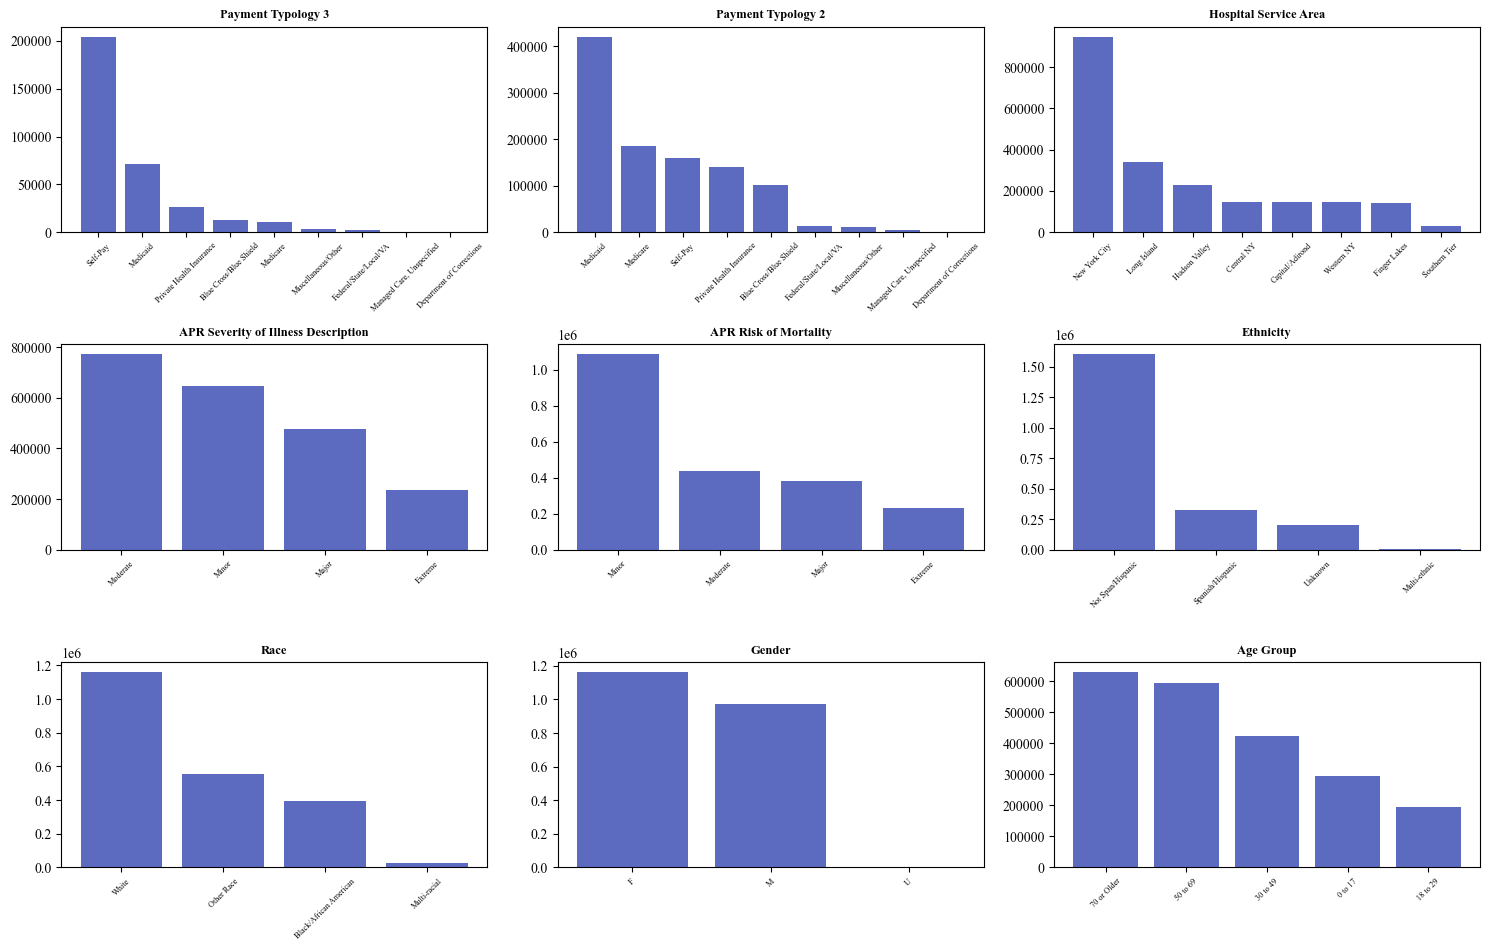

In [16]:
vars_graficables = [c for c in CATEGORICAS
                    if c in df.columns and df[c].nunique() <= 15 and df[c].nunique() > 1]

print(f"Variables graficables (<=15 categorías): {len(vars_graficables)}")
print(vars_graficables)

ncols = 3
nrows = int(np.ceil(len(vars_graficables) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, nrows * 3.2))
axes = np.array(axes).flatten()

for i, c in enumerate(vars_graficables):
    vc = df[c].value_counts(dropna=True).head(10)
    axes[i].bar(vc.index.astype(str), vc.values, color=COLOR_SECONDARY)
    axes[i].set_title(c, fontsize=9, fontweight="bold")
    axes[i].tick_params(axis="x", rotation=45, labelsize=6)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


<div style="background:#1976D2;
padding:15px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h3 style="margin:0;">
6.3 Variables de alta cardinalidad (revisar antes de codificar)
</h3>

</div>

<div style="background:#F5F9FF;
border-left:6px solid #1565C0;
padding:18px;
border-radius:0 0 8px 8px;
font-family:Arial,sans-serif">


Las descripciones de diagnóstico/procedimiento (CCSR, APR DRG/MDC) suelen tener decenas o cientos de
categorías — igual que pasó con los CIE-10 en los datos institucionales. Conviene usar los códigos
(ej. <code>CCSR Diagnosis Code</code>) en vez de las descripciones de texto largo, y evaluar agrupar
categorías poco frecuentes en <code>02_Preprocessing</code>.


</div>

In [28]:
vars_alta_card = [c for c in CATEGORICAS if c in df.columns and df[c].nunique() > 15]

resumen_datos = []
for c in vars_alta_card:
    n_categorias = df[c].nunique()
    print(f"{c}: {n_categorias} categorías")
    resumen_datos.append({"Variable": c, "Num_Categorias": n_categorias})
    
df_vars_alta_card = pd.DataFrame(resumen_datos)
guardar_tabla(df_vars_alta_card, "ResumenVariablesAltaCardinalidad")

Hospital County: 57 categorías
Zip Code - 3 digits: 50 categorías
CCSR Diagnosis Code: 478 categorías
CCSR Diagnosis Description: 478 categorías
CCSR Procedure Code: 321 categorías
CCSR Procedure Description: 321 categorías
APR DRG Code: 334 categorías
APR DRG Description: 334 categorías
APR MDC Code: 26 categorías
APR MDC Description: 26 categorías
Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_ResumenVariablesAltaCardinalidad.csv


In [30]:
print(vars_alta_card)
len(df_vars_alta_card)

['Hospital County', 'Zip Code - 3 digits', 'CCSR Diagnosis Code', 'CCSR Diagnosis Description', 'CCSR Procedure Code', 'CCSR Procedure Description', 'APR DRG Code', 'APR DRG Description', 'APR MDC Code', 'APR MDC Description']


10

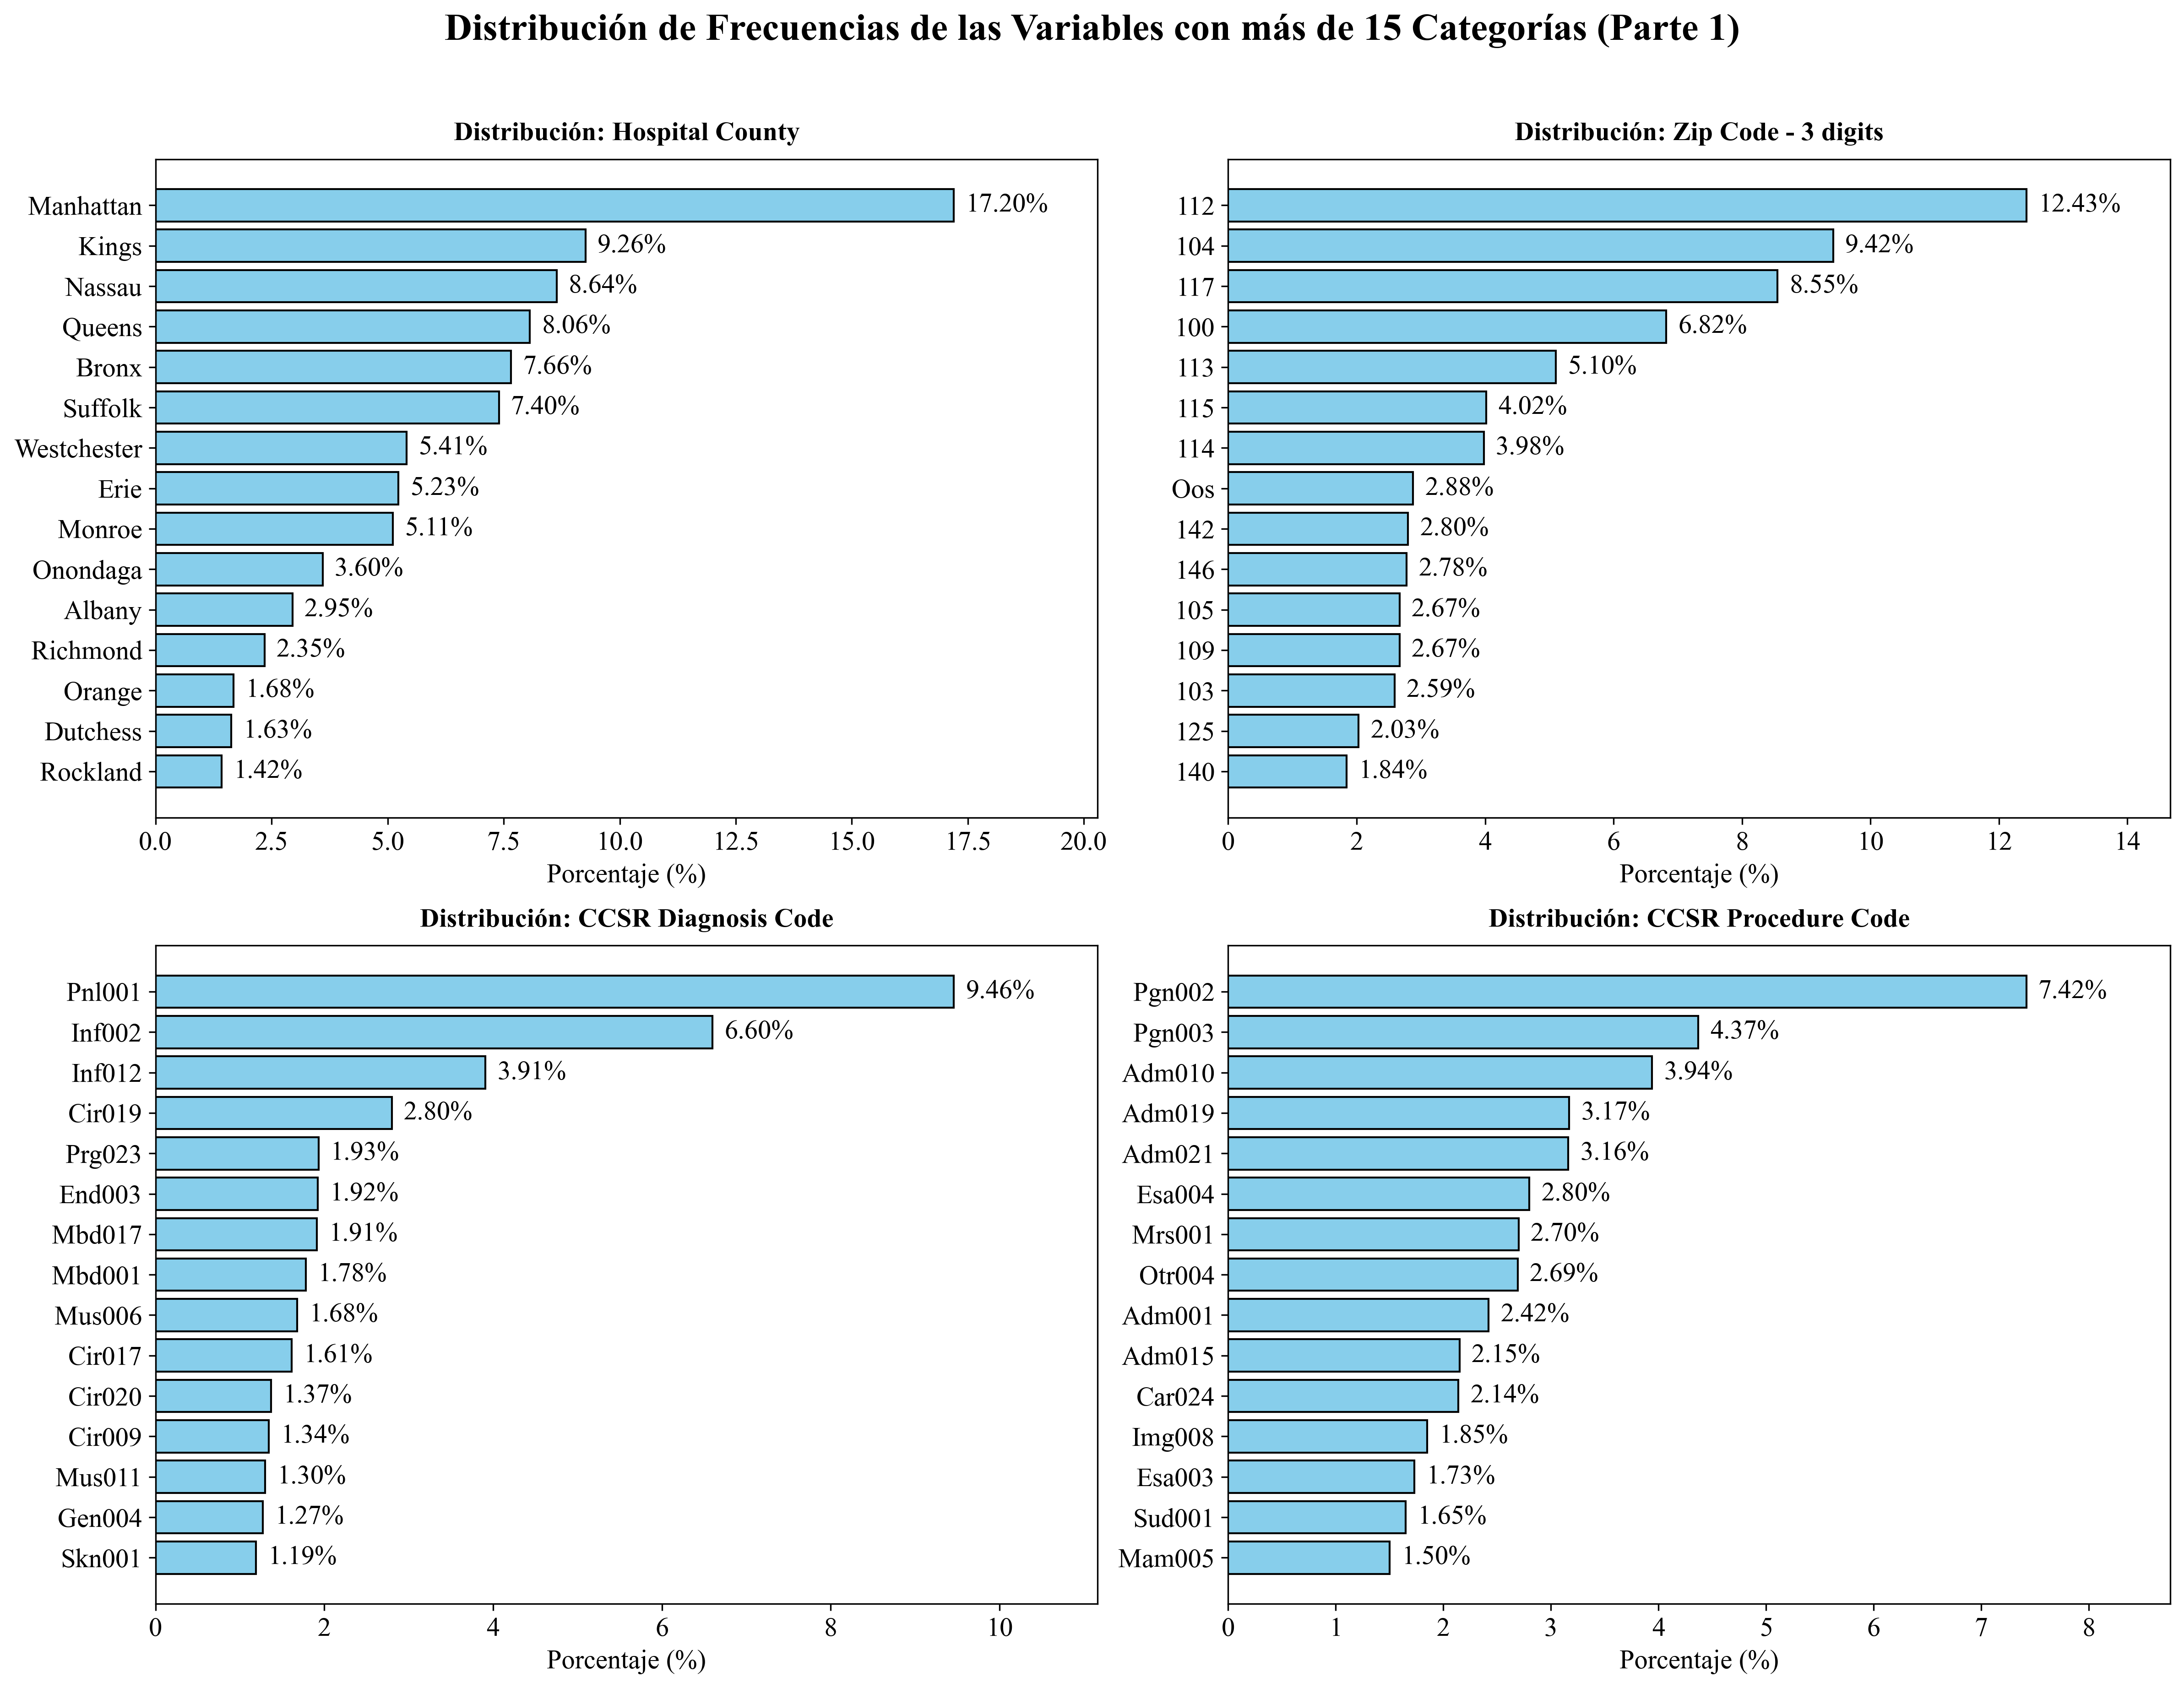

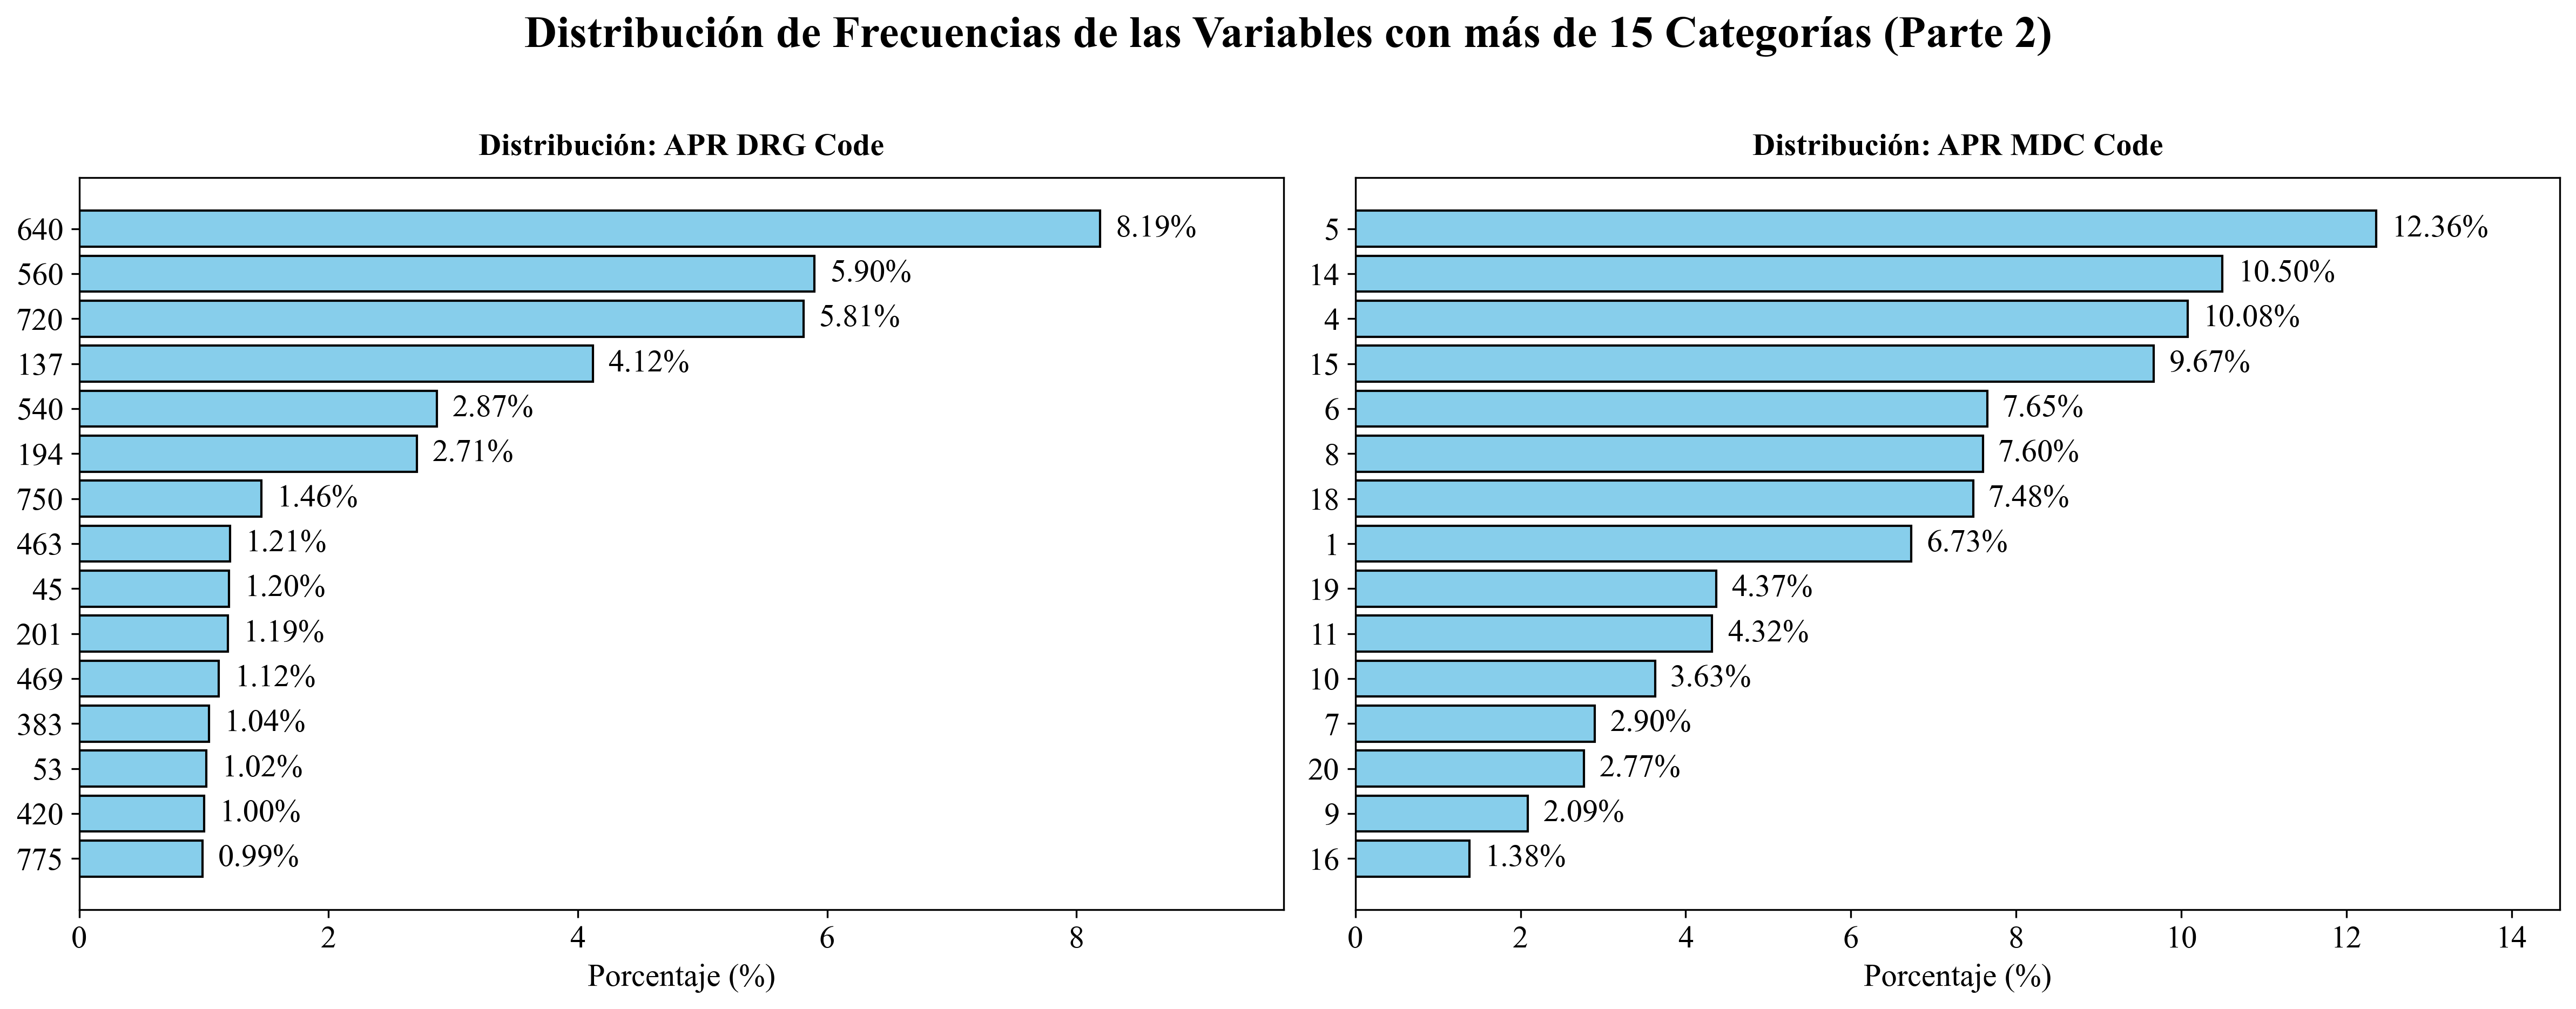

In [39]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Configurar tipografía Times New Roman de forma nativa (compatible con tu tesis)
plt.rcParams.update(
    {
        "text.usetex": False,
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "Liberation Serif"],
        "mathtext.fontset": "stix",
    }
)


# --- FUNCIÓN UNIVERSAL PARA FORMATEAR LAS CATEGORÍAS (Iniciales con punto) ---
def formatear_categoria_tesis(texto):
    if pd.isna(texto):
        return texto
    palabras = str(texto).split()
    if not palabras:
        return ""

    # Primera palabra: inicial en mayúscula, el resto en minúscula
    primera = palabras[0].capitalize()

    # Siguientes palabras: inicial en mayúscula seguida de un punto
    iniciales = [f"{p[0].upper()}." for p in palabras[1:]]

    # Unir la primera palabra con las iniciales restantes
    return " ".join([primera] + iniciales)


# --- Lista original suministrada ---
lista_origen = [
    "Hospital County",
    "Zip Code - 3 digits",
    "CCSR Diagnosis Code",
    "CCSR Procedure Code",
    "APR DRG Code",
    "APR MDC Code",
]

# Dividir la lista en dos bloques para las dos figuras independientes
categoricas_fig3_parte1 = lista_origen[:4]  # 4 variables para la matriz de 2x2
categoricas_fig3_parte2 = lista_origen[4:]  # 2 variables para la matriz de 1x2


# --- FUNCIÓN AUXILIAR PARA GENERAR CADA FIGURA ---
def generar_figura_bloque_codigos(
    lista_variables, filas, columnas, alto_figura, titulo_global, nombre_archivo
):
    fig, axes = plt.subplots(filas, columnas, figsize=(16, alto_figura), dpi=300)

    # Convertir a array plano para iterar sin importar si es de 1D (1 fila) o 2D (varias filas)
    if filas == 1:
        axes_flat = axes
    else:
        axes_flat = axes.flatten()

    idx_plot = 0

    for c in lista_variables:
        if c not in df.columns:
            continue

        s = df[c]
        n_valid = s.notna().sum()
        if n_valid == 0:
            continue

        # Obtener el Top 15 de categorías para evitar saturación visual en la tesis
        vc = s.value_counts(dropna=True).head(15)
        vc_pct = (vc / n_valid * 100).round(2)

        if idx_plot >= len(axes_flat):
            break

        ax = axes_flat[idx_plot]

        # Aplicar la regla de formato de iniciales a TODAS las categorías de este bloque
        categorias = [formatear_categoria_tesis(cat) for cat in vc_pct.index]
        valores = list(vc_pct.values)

        # Invertir el orden para que la barra de mayor porcentaje se posicione arriba
        categorias.reverse()
        valores.reverse()

        # --- Dibujar Gráfica Horizontal ---
        barras = ax.barh(categorias, valores, color="skyblue", edgecolor="black")

        # Configurar límites del eje X dejando un margen del 18% para los textos de porcentaje
        max_valor = max(valores) if valores else 100
        ax.set_xlim(0, max_valor * 1.18 if max_valor > 0 else 100)

        # Configuración de etiquetas de los ejes (Tamaño 14)
        ax.set_xlabel("Porcentaje (%)", fontsize=14)

        # Añadir las etiquetas de porcentaje al final de cada barra horizontal (Tamaño 14)
        for barra in barras:
            ancho = barra.get_width()
            ax.text(
                ancho + (max_valor * 0.015),  # Espaciado estético a la derecha de la barra
                barra.get_y() + barra.get_height() / 2,
                f"{ancho:.2f}%",
                va="center",
                ha="left",
                fontsize=14,
                fontfamily="serif",
            )

        # Configuración de títulos individuales y tamaños de fuente normativos
        ax.set_title(f"Distribución: {c}", fontsize=14, fontweight="bold", pad=10)
        ax.tick_params(
            axis="y", labelsize=14
        )  # Tamaño 14 para asegurar la lectura de las iniciales abreviadas
        ax.tick_params(axis="x", labelsize=14)

        idx_plot += 1

    # Eliminar páneles vacíos si alguna variable no se encontrara en tu DataFrame
    for j in range(idx_plot, len(axes_flat)):
        fig.delaxes(axes_flat[j])

    # Título global superior para toda la figura
    fig.suptitle(
        titulo_global,
        fontsize=20,
        fontweight="bold",
        y=1.03 if filas == 1 else 1.02,  # Ajustar la altura del título para evitar empalmes
    )

    # Optimizar espacios de márgenes para la integración final en LaTeX
    plt.tight_layout()
    plt.savefig(nombre_archivo, bbox_inches="tight")
    plt.show()


# =====================================================================
# --- FIGURA 3 (Parte 1): 2 filas x 2 columnas (4 variables) ---
# =====================================================================
generar_figura_bloque_codigos(
    lista_variables=categoricas_fig3_parte1,
    filas=2,
    columnas=2,
    alto_figura=12,  # Escala idéntica de proporciones para 2 filas
    titulo_global="Distribución de Frecuencias de las Variables con más de 15 Categorías (Parte 1)",
    nombre_archivo="distribucion_categoricas_parte3_2x2.pdf",
)

# =====================================================================
# --- FIGURA 3 (Parte 2): 1 fila x 2 columnas (2 variables restantes) ---
# =====================================================================
generar_figura_bloque_codigos(
    lista_variables=categoricas_fig3_parte2,
    filas=1,
    columnas=2,
    alto_figura=6,  # Altura reducida a la mitad exacta para mantener el grosor de las barras
    titulo_global="Distribución de Frecuencias de las Variables con más de 15 Categorías (Parte 2)",
    nombre_archivo="distribucion_categoricas_parte3_1x2.pdf",
)

<div style="background:#1A237E;
padding:18px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h2 style="margin:0;">
7. Variables numéricas: Birth Weight
</h2>

</div>

<div style="background:#F5F9FF;
border-left:6px solid #1565C0;
padding:18px;
border-radius:0 0 8px 8px;
font-family:Arial,sans-serif">


Según el diccionario, estas tres llegan como texto (<code>Char</code>), probablemente con símbolos de
moneda o comas de miles en <code>Total Charges</code>/<code>Total Costs</code>. Se limpian aquí solo
para poder describirlas.


</div>

In [18]:
def limpiar_numerico(serie):
    return pd.to_numeric(
        serie.astype(str).str.replace(r"[\$,]", "", regex=True).str.strip(),
        errors="coerce"
    )

resumen_numericas = {}
for c in NUMERICAS:
    if c not in df.columns:
        continue
    s = limpiar_numerico(df[c])
    n_valid = s.notna().sum()
    print(f"=== {c} (n_validos={n_valid:,}, nulos={ (len(s)-n_valid)/len(s)*100:.1f}%) ===")
    desc = s.dropna().describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(2)
    print(desc)
    print()
    resumen_numericas[c] = desc

resumen_numericas_df = pd.DataFrame(resumen_numericas)
guardar_tabla(resumen_numericas_df, "ResumenNumericas")


=== Birth Weight (n_validos=209,805, nulos=90.2%) ===
count    209805.00
mean       3191.89
std         585.24
min         400.00
5%         2200.00
25%        2900.00
50%        3200.00
75%        3600.00
95%        4000.00
99%        4400.00
max        9000.00
Name: Birth Weight, dtype: float64

Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_ResumenNumericas.csv


<div style="background:#F5F9FF;
border-left:6px solid #1565C0;
padding:18px;
border-radius:0 0 8px 8px;
font-family:Arial,sans-serif">


<code>Birth Weight</code> va a tener un porcentaje muy alto de nulos/ceros — solo aplica a los
recién nacidos (Type of Admission = "Newborn"). No es un error, es esperado.


</div>

<div style="background:#1A237E;
padding:18px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h2 style="margin:0;">
8. Identificadores y variables sin variabilidad (candidatas a eliminar)
</h2>

</div>

In [19]:
print("=== Identificadores ===")
resumen_identificadores = []
for c in IDENTIFICADORES:
    if c not in df.columns:
        continue
    ejemplo = df[c].dropna().unique()[:3].tolist()
    print(f"{c}: {df[c].nunique()} valores únicos, {df[c].isna().mean()*100:.1f}% nulos")
    print(f"  Ejemplo de valores: {ejemplo}")
    print()
    resumen_identificadores.append({
        "variable": c,
        "n_unicos": df[c].nunique(),
        "pct_nulos": round(df[c].isna().mean() * 100, 2),
        "ejemplo_valores": str(ejemplo),
    })

print("=== Variables constantes (nunique <= 1) en todo el dataset ===")
constantes = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
print(constantes if constantes else "Ninguna")

resumen_identificadores_df = pd.DataFrame(resumen_identificadores)
guardar_tabla(resumen_identificadores_df, "Identificadores")


=== Identificadores ===
Operating Certificate Number: 168 valores únicos, 0.3% nulos
  Ejemplo de valores: [7000006.0, 7002001.0, 7001009.0]

Permanent Facility Id: 204 valores únicos, 0.2% nulos
  Ejemplo de valores: [1169.0, 1168.0, 3058.0]

Facility Name: 204 valores únicos, 0.0% nulos
  Ejemplo de valores: ['Montefiore Medical Center - Henry & Lucy Moses Div', 'Montefiore Medical Center-Wakefield Hospital', 'Montefiore Med Center - Jack D Weiler Hosp of A Einstein College Div']

=== Variables constantes (nunique <= 1) en todo el dataset ===
['Discharge Year']
Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_Identificadores.csv


<div style="background:#F5F9FF;
border-left:6px solid #1565C0;
padding:18px;
border-radius:0 0 8px 8px;
font-family:Arial,sans-serif">


<code>Facility Name</code> probablemente aparezca como <code>"Redacted for Confidentiality"</code> en
una proporción importante de registros (los de "enhanced de-identification") — si tiene muy poca
variabilidad real, es candidata a eliminar junto con <code>Operating Certificate Number</code> y
<code>Permanent Facility Id</code> (identificadores puros, sin valor predictivo).


</div>

<div style="background:#1A237E;
padding:18px;
border-radius:8px;
color:white;
font-family:Arial,sans-serif">

<h2 style="margin:0;">
9. Síntesis: variables que pasan a Preprocessing
</h2>

</div>

In [20]:
variables_conservar = [OBJETIVO] + CATEGORICAS + NUMERICAS
variables_eliminar = IDENTIFICADORES + constantes + VARIABLES_PAGO

print(f"Variables a conservar para 02_Preprocessing ({len(variables_conservar)}):")
print(variables_conservar)
print()
print(f"Variables a eliminar ({len(set(variables_eliminar))}):")
print(sorted(set(variables_eliminar)))

sintesis_df = pd.DataFrame(
    [{"variable": v, "accion": "conservar"} for v in variables_conservar] +
    [{"variable": v, "accion": "eliminar"} for v in sorted(set(variables_eliminar))]
)
guardar_tabla(sintesis_df, "SintesisVariables")


Variables a conservar para 02_Preprocessing (15):
['Length of Stay', 'Payment Typology 3', 'Payment Typology 2', 'CCSR Procedure Code', 'Zip Code - 3 digits', 'Hospital Service Area', 'Hospital County', 'APR Severity of Illness Description', 'APR Risk of Mortality', 'Ethnicity', 'Race', 'Gender', 'Age Group', 'APR MDC Description', 'Birth Weight']

Variables a eliminar (7):
['Discharge Year', 'Facility Name', 'Operating Certificate Number', 'Patient Disposition', 'Permanent Facility Id', 'Total Charges', 'Total Costs']
Tabla guardada: C:\Users\danie\OneDrive - Universidad Externado de Colombia\Tesis\SPARCS\tablas\01_SintesisVariables.csv


<div style="background:#FFF5F5;
border-left:6px solid #C62828;
padding:18px;
border-radius:0 0 8px 8px;
font-family:Arial,sans-serif">


Esta lista es solo documentación de lo encontrado en el EDA — <b>la eliminación real de columnas,
limpieza de <code>Length of Stay</code> y de los campos numéricos con símbolos, y cualquier
imputación se hacen en <code>02_Preprocessing.ipynb</code></b>, no aquí.


</div>